# Paper 2: market regimes on Crypto Matter data

This notebook runs the Paper 2 model (rolling covariance → PCA → Ward clustering into calm / high volatility)
in four versions on the **same period**, and compares them:

| Version | Data | Question it answers |
|---|---|---|
| **Yahoo** | BTC, ETH, S&P 500, gold, US 10Y yield, VIX, all from Yahoo | Our earlier result (the baseline) |
| **CM** | BTC and ETH from Crypto Matter (dates fixed), market data from Yahoo | Does the result hold on the official data? |
| **Crypto-only** | BTC, ETH, LTC, BNB, XMR, all from Crypto Matter (dates fixed) | Does a crypto basket catch crypto-only stress, e.g. May 2021? |
| **Benchmark** | BTC's own 21-day volatility vs its past median | A simple rule to compare against |

**Before running:** in the terminal (the API key is only needed there), run
`python fetch_data.py` and then `python cm_data.py --coins bitcoin ethereum litecoin binancecoin monero`.
Then **Run All** (about 2 minutes). The notebook never needs the key.

In [17]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown

import config
from data_prep import align, to_returns
from features import rolling_features
from model import walk_forward, smooth, team_output
from backtest import regime_table, stress_check, strategy_test
from plots import plot_regimes

pd.set_option("display.width", 160)
OUT = "outputs_notebook"
os.makedirs(OUT, exist_ok=True)

COINS = {"bitcoin": "BTC", "ethereum": "ETH", "litecoin": "LTC", "binancecoin": "BNB", "monero": "XMR"}
SHIFT_START, SHIFT_END = "2018-01-28", "2023-11-22"   # CM dates are one day late here (confirmed with Tobias)

# The same time spans, counted in rows of each calendar
BUSINESS = dict(window=21, min_train=504, refit=21, min_stay=5, horizon=20, fast=30, slow=100, per_year=252)
EVERYDAY = dict(window=30, min_train=730, refit=30, min_stay=7, horizon=28, fast=42, slow=140, per_year=365)

needed = ["data/raw_prices.csv"] + [f"data/cm/{c}_Close.csv" for c in COINS]
missing = [f for f in needed if not os.path.exists(f)]
assert not missing, f"Missing {missing}: run fetch_data.py and cm_data.py first (see the top of the notebook)"
print("All input files found.")

All input files found.


## 1. Load the data and fix Crypto Matter's dates

* Zero prices are errors in the source, so they become missing.
* CM rows dated **28 Jan 2018 – 22 Nov 2023** are moved back one day. If a moved row lands on a date that already
  has a row (27 Jan 2018), the original row is kept.
* Short gaps (up to 3 days) are filled later, inside each model run, as Tobias allowed.

In [18]:
def load_cm(coin, fix_dates=True):
    s = pd.read_csv(f"data/cm/{coin}_Close.csv", parse_dates=["date"], index_col="date")["Close"]
    s = s.where(s > 0)                                                  # zero price -> missing
    if fix_dates:
        late = (s.index >= SHIFT_START) & (s.index <= SHIFT_END)
        new_dates = pd.DatetimeIndex(np.where(late, s.index - pd.Timedelta(days=1), s.index))
        df = pd.DataFrame({"value": s.to_numpy(), "moved": late}, index=new_dates)
        df = df.sort_values("moved", kind="stable")                     # originals first
        df = df[~df.index.duplicated(keep="first")].sort_index()
        s = df["value"]
    s.index.name = "date"
    return s.rename(COINS[coin])

yahoo = pd.read_csv("data/raw_prices.csv", parse_dates=["date"], index_col="date")
cm_raw = {c: load_cm(c, fix_dates=False) for c in COINS}
cm = {c: load_cm(c) for c in COINS}

coverage = pd.DataFrame({COINS[c]: {"first date": s.dropna().index.min().date(),
                                    "last date": s.dropna().index.max().date(),
                                    "days with a price": int(s.notna().sum())} for c, s in cm.items()}).T
coverage.loc["Yahoo market data"] = [yahoo["SPX"].dropna().index.min().date(),
                                     yahoo["SPX"].dropna().index.max().date(), int(yahoo["SPX"].notna().sum())]
display(coverage)

,first date,last date,days with a price
BTC,2013-04-29,2026-11-22,4811
ETH,2015-08-07,2026-11-22,4019
LTC,2013-04-29,2026-11-22,4809
BNB,2017-09-16,2026-11-22,3287
XMR,2014-05-21,2026-11-22,4439
Yahoo market data,2017-11-10,2026-11-20,2269


### Check: does the date fix work?

Correlation of BTC's daily returns, Crypto Matter vs Yahoo, **on the same date**. Before the fix it is near 0 in
2018–2023 (the dates are one day apart); after the fix it should be close to 1 in every year.

In [19]:
def same_day_corr(a, b):
    cal = pd.date_range(max(a.index.min(), b.index.min()), min(a.index.max(), b.index.max()))
    r = np.log(pd.DataFrame({"cm": a, "y": b}).reindex(cal)).diff()
    return r.groupby(r.index.year).apply(lambda g: g["cm"].corr(g["y"])).round(2)

y_btc = yahoo["BTC"].dropna()
date_check = pd.DataFrame({"before fix": same_day_corr(cm_raw["bitcoin"], y_btc),
                           "after fix": same_day_corr(cm["bitcoin"], y_btc)})
date_check.index.name = "year"
display(date_check)

,before fix,after fix
year,,
2017,0.87,0.87
2018,0.10,0.96
2019,-0.01,0.98
2020,-0.11,0.98
2021,-0.06,0.99
2022,-0.02,1.00
2023,0.09,0.99
2024,0.98,0.98
2025,0.98,0.98


## 2. Run the four versions

`align` keeps the stock-market days when the S&P 500 is in the basket (otherwise every day), fills gaps of up to
3 days and starts when every asset has data. Each version is refitted monthly on past data only.

In [20]:
def run_version(prices, calendar, p):
    px = align(prices, calendar)
    rets = to_returns(px, [c for c in config.YIELD_COLS if c in px])
    feats, aux = rolling_features(rets, p["window"], config.FEATURE_SET)
    p_high, diags, _ = walk_forward(feats, aux, p["min_train"], p["refit"], config.N_PCS, config.N_REGIMES)
    _, regime = smooth(p_high, p["min_stay"])
    return {"px": px, "close": px["BTC"], "p_high": p_high, "regime": regime, "diags": diags, "p": p}

market = yahoo[["SPX", "GOLD", "US10Y", "VIX"]]
versions = {}
versions["Yahoo"] = run_version(yahoo[list(config.BASKET)], "SPX", BUSINESS)
versions["CM"] = run_version(pd.concat([cm["bitcoin"], cm["ethereum"], market], axis=1, sort=True), "SPX", BUSINESS)
versions["Crypto-only"] = run_version(pd.concat(list(cm.values()), axis=1, sort=True), None, EVERYDAY)

# Benchmark: BTC's own 21-day volatility above its median so far (CM data, stock-market days)
cm_close = versions["CM"]["close"]
vol = np.log(cm_close).diff().rolling(BUSINESS["window"]).std()
bench_raw = (vol > vol.expanding(min_periods=BUSINESS["min_train"]).median().shift(1)).astype(float)
bench_raw = bench_raw[vol.expanding(min_periods=BUSINESS["min_train"]).median().shift(1).notna()]
_, bench_regime = smooth(bench_raw, BUSINESS["min_stay"])
versions["Benchmark"] = {"close": cm_close, "regime": bench_regime, "p": BUSINESS}

for name, v in versions.items():
    r = v["regime"]
    print(f"{name:12s} labelled {len(r):5d} days, {r.index.min().date()} to {r.index.max().date()}")

Yahoo        labelled  1744 days, 2019-12-13 to 2026-11-20
CM           labelled  1744 days, 2019-12-13 to 2026-11-20
Crypto-only  labelled  2537 days, 2019-11-23 to 2026-11-22
Benchmark    labelled  1744 days, 2019-12-13 to 2026-11-20


## 3. Compare on the same period

**How to read it**
* **BTC volatility next month after HIGH vs after CALM**: the key test. A useful high-volatility label should be
  followed by clearly higher volatility.
* **Crash caught**: share of days inside each known crash labelled high volatility.
* **Switches per year**: a few is healthy; dozens would be noise.
* **Sharpe**: the paper's trading idea (skip a simple trend rule in high volatility), 0.1% cost per trade.

In [21]:
start = max(v["regime"].index.min() for v in versions.values())
end = min(v["regime"].index.max() for v in versions.values())
print(f"Common period: {start.date()} to {end.date()}")

def metrics(v):
    reg, close, p = v["regime"].loc[start:end], v["close"], v["p"]
    nv = f"next_{p['horizon']}d_volatility"
    tab = regime_table(reg, close, p["horizon"], p["per_year"])
    stress = stress_check(reg, config.STRESS_WINDOWS)
    strat, _ = strategy_test(close.loc[:end], reg, p["fast"], p["slow"], config.COST, p["per_year"])
    out = {"high-vol share of days": (reg == "high_vol").mean(),
           "switches per year": ((reg != reg.shift()).sum() - 1) / (len(reg) / p["per_year"]),
           "BTC vol next month after HIGH": tab[nv].get("high_vol", np.nan),
           "BTC vol next month after CALM": tab[nv].get("low_vol", np.nan)}
    out["difference (HIGH minus CALM)"] = out["BTC vol next month after HIGH"] - out["BTC vol next month after CALM"]
    for k, val in stress.items():
        out[f"crash caught: {k}"] = val
    out["Sharpe: trend rule alone"] = strat.loc["Trend rule (30/100 MA)", "sharpe"]
    out["Sharpe: trend rule + regime filter"] = strat.loc["Trend rule + regime filter", "sharpe"]
    out["cluster silhouette (avg)"] = v["diags"]["silhouette"].mean() if "diags" in v else np.nan
    return pd.Series(out)

results = pd.DataFrame({name: metrics(v) for name, v in versions.items()})
plain = {"switches per year", "Sharpe: trend rule alone", "Sharpe: trend rule + regime filter",
         "cluster silhouette (avg)"}
shown = results.copy().astype(object)
for row in shown.index:
    shown.loc[row] = ["" if pd.isna(x) else (f"{x:.2f}" if row in plain else f"{x:+.0%}" if "difference" in row
                      else f"{x:.0%}") for x in results.loc[row]]
display(shown)
results.to_csv(f"{OUT}/comparison.csv")

Common period: 2019-12-13 to 2026-11-20


,Yahoo,CM,Crypto-only,Benchmark
high-vol share of days,67%,68%,18%,27%
switches per year,6.50,5.35,4.64,4.91
BTC vol next month after HIGH,54%,56%,47%,63%
BTC vol next month after CALM,55%,52%,56%,51%
difference (HIGH minus CALM),-0%,+4%,-9%,+12%
crash caught: COVID crash (Mar 2020),88%,59%,0%,59%
crash caught: May 2021 crypto crash,0%,100%,12%,100%
crash caught: Terra/LUNA (May-Jun 2022),100%,72%,0%,85%
crash caught: FTX collapse (Nov 2022),100%,100%,29%,65%
Sharpe: trend rule alone,0.68,0.68,0.64,0.68


## 4. Charts

C:\Users\mainak\AppData\Local\Temp\ipykernel_20848\1504442540.py:17: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


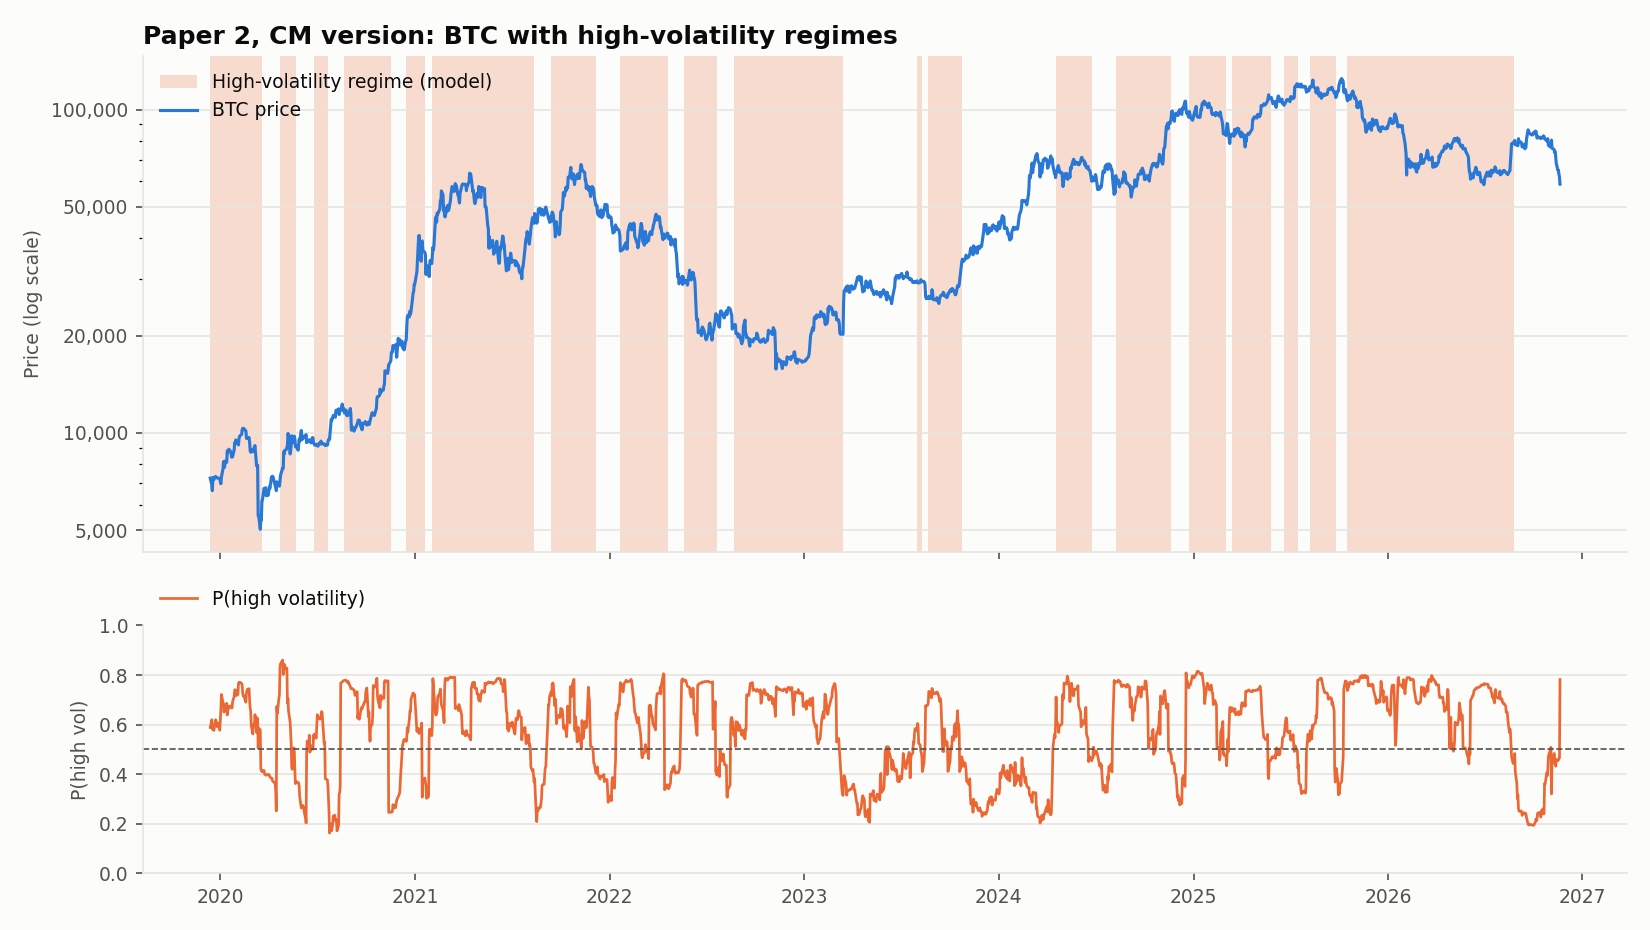

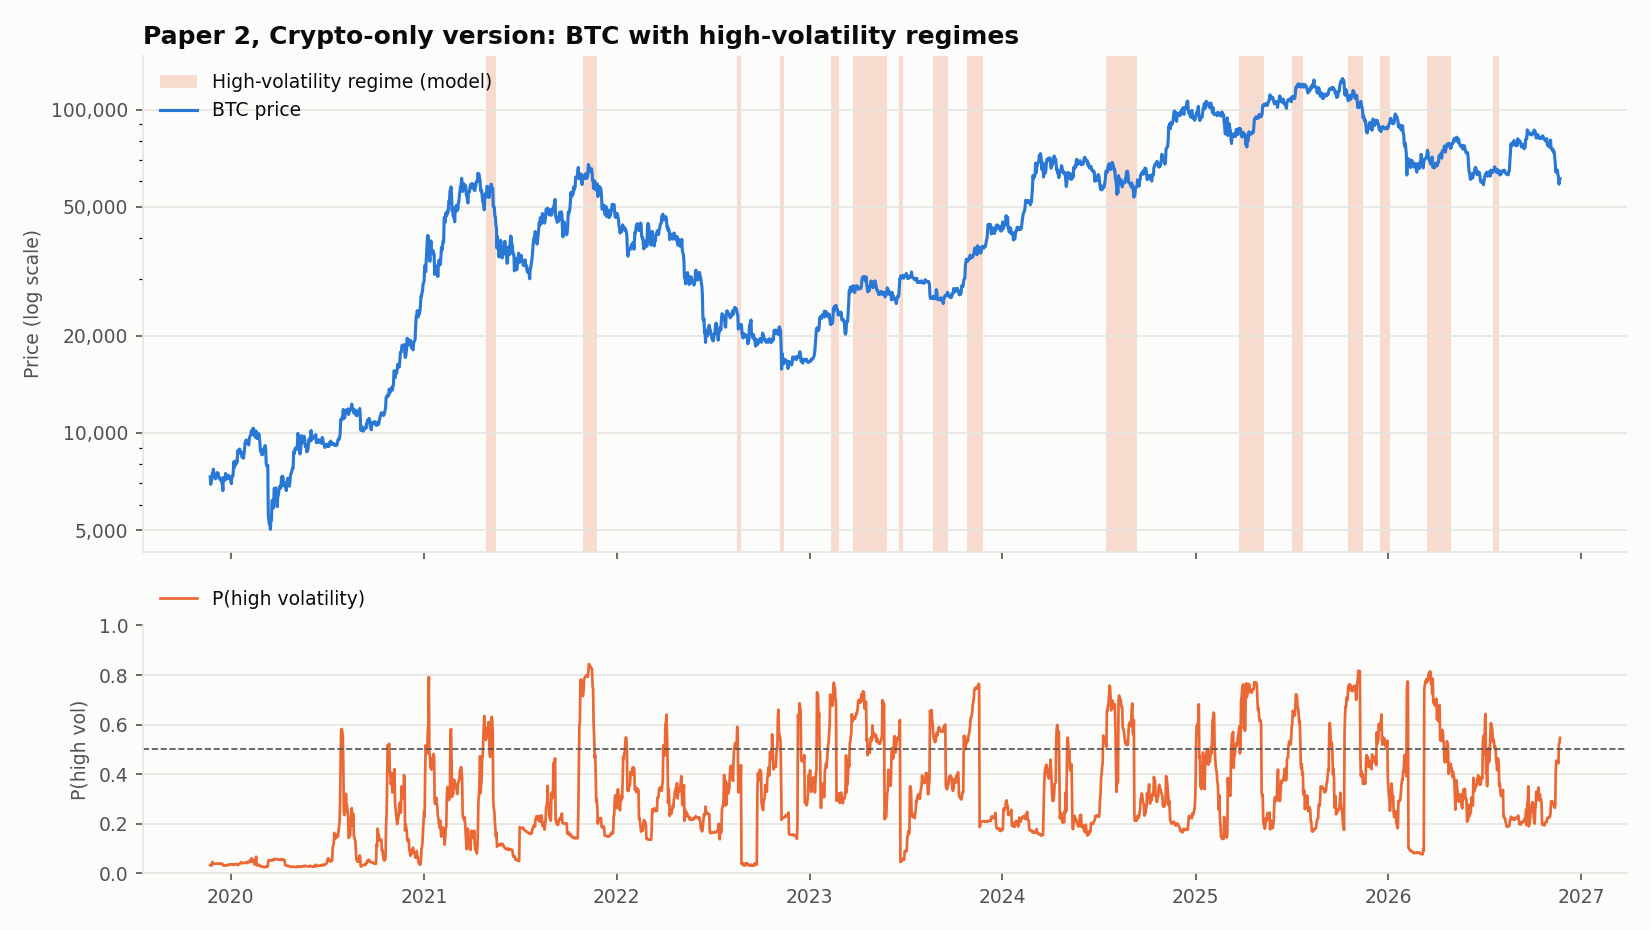

In [22]:
fig, ax = plt.subplots(figsize=(9, 4))
names = list(results.columns)
x = np.arange(len(names))
ax.bar(x - 0.2, results.loc["BTC vol next month after HIGH"] * 100, 0.4, color="#eb6834", label="after HIGH label")
ax.bar(x + 0.2, results.loc["BTC vol next month after CALM"] * 100, 0.4, color="#2a78d6", label="after CALM label")
ax.set_xticks(x)
ax.set_xticklabels(names)
ax.set_ylabel("BTC volatility next month (%, annualised)")
ax.set_title(f"Does the label predict Bitcoin's next-month volatility? ({start.year}-{end.year})", loc="left")
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.0f%%", fontsize=9, padding=2)
ax.legend(frameon=False, ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.1))
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
fig.tight_layout()
fig.savefig(f"{OUT}/chart_next_month_volatility.png", dpi=130)
plt.show()

for name in ["CM", "Crypto-only"]:
    v = versions[name]
    path = f"{OUT}/chart_regimes_{name.lower().replace('-', '_')}.png"
    plot_regimes(v["close"], v["p_high"], v["regime"], path, f"Paper 2, {name} version: BTC with high-volatility regimes")
    display(Image(path))

## 5. Save the team output tables

Same format as before (`date, p_bull, p_bear, p_low_vol, p_high_vol`; no bull/bear from this model).

In [23]:
team_output(versions["CM"]["p_high"]).to_csv(f"{OUT}/paper2_output_cm.csv")
team_output(versions["Crypto-only"]["p_high"]).to_csv(f"{OUT}/paper2_output_crypto_only.csv")
print("Saved in", OUT, ":", sorted(os.listdir(OUT)))

Saved in outputs_notebook : ['chart_next_month_volatility.png', 'chart_regimes_cm.png', 'chart_regimes_crypto_only.png', 'comparison.csv', 'paper2_output_cm.csv', 'paper2_output_crypto_only.csv']


## 6. Key numbers for the team update

In [24]:
def pct(name, row):
    return f"{results.loc[row, name]:.0%}"

lines = [f"Common period: {start.date()} to {end.date()}", ""]
for name in results.columns:
    lines.append(f"{name}: BTC vol next month {pct(name, 'BTC vol next month after HIGH')} after HIGH vs "
                 f"{pct(name, 'BTC vol next month after CALM')} after CALM; high-vol on "
                 f"{pct(name, 'high-vol share of days')} of days")
    crash = [f"{k.replace('crash caught: ', '').split(' (')[0]} {results.loc[k, name]:.0%}"
             for k in results.index if k.startswith("crash caught")]
    lines.append("   crashes caught: " + ", ".join(crash))
print("\n".join(lines))

Common period: 2019-12-13 to 2026-11-20

Yahoo: BTC vol next month 54% after HIGH vs 55% after CALM; high-vol on 67% of days
   crashes caught: COVID crash 88%, May 2021 crypto crash 0%, Terra/LUNA 100%, FTX collapse 100%
CM: BTC vol next month 56% after HIGH vs 52% after CALM; high-vol on 68% of days
   crashes caught: COVID crash 59%, May 2021 crypto crash 100%, Terra/LUNA 72%, FTX collapse 100%
Crypto-only: BTC vol next month 47% after HIGH vs 56% after CALM; high-vol on 18% of days
   crashes caught: COVID crash 0%, May 2021 crypto crash 12%, Terra/LUNA 0%, FTX collapse 29%
Benchmark: BTC vol next month 63% after HIGH vs 51% after CALM; high-vol on 27% of days
   crashes caught: COVID crash 59%, May 2021 crypto crash 100%, Terra/LUNA 85%, FTX collapse 65%


## 7. Observations and conclusion (Mainak, 23 Nov 2026)

**Key test (BTC volatility over the next month, after a HIGH vs a CALM label, Dec 2019 – Nov 2026):**
CM version 56% vs 52% (+4 pts) · Yahoo version 54% vs 55% (≈0) · Crypto-only 47% vs 56% (−9) · Benchmark (BTC's own volatility) 63% vs 51% (+12)

1. **The date fix works.** After moving CM dates from 28 Jan 2018 to 22 Nov 2023 back one day, CM and Yahoo BTC match on the same date in every year (0.96–1.00, before: about 0).
2. **Paper 2 picks up market-wide stress, not Bitcoin's own volatility.** It separates next-month volatility by only +4 pts, against +12 for the simple benchmark.
3. **It labels about two thirds of days as HIGH volatility**, which is too often to be a warning on its own.
4. **It is sensitive to small data differences.** Yahoo and CM prices differ by only 0.1–0.2%, yet the results shift a lot (May 2021 crash: 0% vs 100%). Cluster quality is weak (silhouette 0.28).
5. **The crypto-only version does not help.** Its labels point the wrong way and it misses most crashes, so Paper 2's signal comes from the link between crypto and traditional markets.
6. **Trading test:** skipping a simple trend strategy in HIGH periods lowers its Sharpe ratio (0.68 → 0.49 on CM data).

**Conclusion:** use the CM version of Paper 2 as a market-stress input to the combiner, not as a standalone Bitcoin regime model. Output table: `outputs_notebook/paper2_output_cm.csv`.